# TP 1 — Construire un pipeline NLP classique

**Cours NLP et Transformers — CY Tech**

---

## Avant de commencer

**Faites tout de suite : `Fichier` → `Enregistrer une copie dans Drive`.**
Sans cela vous travaillez sur une copie temporaire et vous perdrez tout en fermant l'onglet.

## Objectif

Construire un pipeline de classification de texte **complet et correctement évalué**, de bout en bout :

`texte brut → prétraitement → représentation → modèle → mesure`

Le but n'est pas d'obtenir le meilleur score. Le but est que **chaque décision du pipeline soit justifiée** et que le score annoncé soit crédible.

## Ce qui est attendu

1. Un jeu de données étiqueté construit à partir du corpus brut
2. Un prétraitement et une représentation TF–IDF
3. Une **baseline** avant tout modèle
4. **Au moins deux modèles** de machine learning comparés
5. Une évaluation avec accuracy, précision, rappel, F1 et matrice de confusion
6. Une **analyse des erreurs** rédigée (partie 8) — c'est la partie la plus importante

## Les deux erreurs qui coûtent des points

- Vectoriser **avant** de découper train/test → fuite de données, tout le TP est invalidé
- Afficher une matrice de confusion sans la commenter

---

## 0. Environnement

Rien à installer : tout est déjà présent dans Colab. Exécutez simplement la cellule.

In [1]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

Le corpus **Tiny Shakespeare** : environ 40 000 lignes extraites de plusieurs pièces de Shakespeare.

C'est du **texte brut, sans aucune étiquette**. C'est volontaire : une grande partie du travail d'un data scientist consiste à transformer une matière première non structurée en un problème d'apprentissage bien posé.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

**Avant d'écrire quoi que ce soit, regardez vos données.** C'est la première règle du métier, et c'est celle qu'on saute le plus souvent.

Affichez un extrait plus long et répondez aux questions ci-dessous.

In [3]:
# extrait un peu plus long, pour voir comment les répliques s'enchaînent
print(texte[1000:2500])


Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

**Questions — répondez ici avant de continuer :**

1. Quelle est la structure répétitive du texte ? Qu'est-ce qui sépare deux blocs ?
2. Quelle information exploitable comme étiquette est déjà présente dans le texte ?
3. Cette étiquette existait-elle vraiment, ou faut-il l'annoter à la main ?

> *Réponses :*
>
> 1. Le texte est une suite de blocs séparés par une ligne vide. Un bloc commence par un nom en majuscules suivi de deux-points, puis la réplique, parfois sur plusieurs lignes.
> 2. Le nom du locuteur, déjà écrit en tête du bloc.
> 3. Elle est déjà dans le texte. Pas besoin de l'annoter à la main : c'est la mise en page qui donne la cible.


## 3. Construire le jeu de données étiqueté

La fonction de parsing vous est donnée : ce n'est pas l'objet du TP, et une regex mal réglée vous ferait perdre une heure.

**Lisez-la quand même**, vous devrez justifier ce qu'elle garde et ce qu'elle jette.

In [4]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte).

    Format attendu dans le corpus :

        NOM DU LOCUTEUR:
        première ligne de la réplique
        seconde ligne de la réplique

    Les blocs sont séparés par une ligne vide.
    """
    lignes = []
    n_blocs = 0
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        n_blocs += 1
        parties = bloc.split("\n")
        # on ne garde que les blocs dont la première ligne est "NOM:"
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    print(f"blocs lus : {n_blocs}, répliques gardées : {len(lignes)}, jetés : {n_blocs - len(lignes)}")
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)


blocs lus : 7222, répliques gardées : 7094, jetés : 128
7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


> La fonction garde un bloc seulement si la première ligne est un nom suivi de deux-points (majuscule au début, lettres, apostrophes et espaces), et s'il y a au moins une ligne de réplique derrière. Elle jette les didascalies, les titres d'acte et les blocs vides. Ici 128 blocs sur 7 222, soit moins de 2 %.


### 3.1 Explorer la distribution

Avant de choisir votre tâche, il faut savoir à quoi ressemble la distribution des classes.

locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
JULIET               124
LEONTES              124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
KING RICHARD II       98
WARWICK               98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64
count    7094.0
mean       27.2
std        39.1
min         1.0
25%         7.0
50%        14.0
75%        32.0
max       578.0
Name: n_mots, dtype: float64


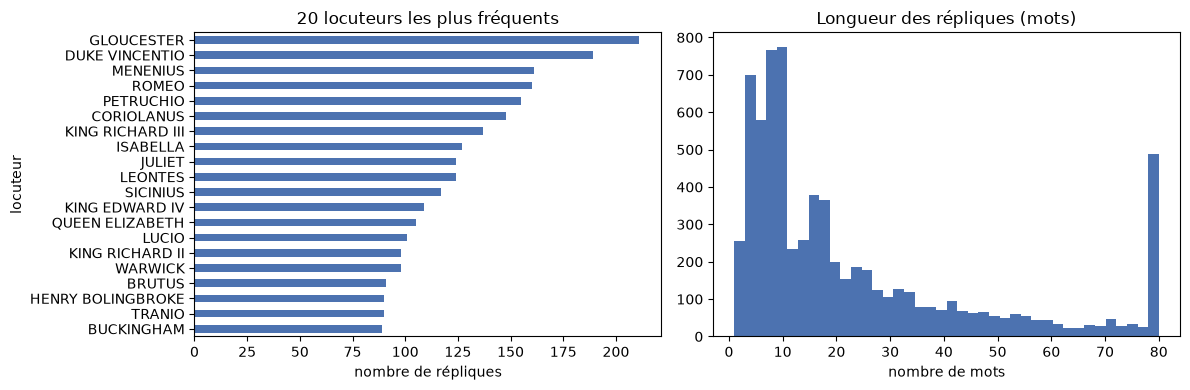

In [5]:
# les 20 personnages qui parlent le plus
top20 = df["locuteur"].value_counts().head(20)
print(top20)

# longueur en mots
df["n_mots"] = df["replique"].str.split().str.len()
print(df["n_mots"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top20.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].invert_yaxis()
axes[0].set_title("20 locuteurs les plus fréquents")
axes[0].set_xlabel("nombre de répliques")
# on coupe l'affichage à 80 mots, sinon les rares tirades écrasent l'histogramme
axes[1].hist(df["n_mots"].clip(upper=80), bins=40, color="#4C72B0")
axes[1].set_title("Longueur des répliques (mots)")
axes[1].set_xlabel("nombre de mots")
plt.tight_layout()
plt.show()


**Questions :**

1. La distribution des locuteurs est-elle équilibrée ? Que se passerait-il si vous gardiez les 297 locuteurs ?
2. Quelle est la longueur médiane d'une réplique ? Est-ce beaucoup pour de la classification de texte ?
3. Quelle conséquence cette longueur aura-t-elle sur votre vecteur TF–IDF ?

> *Réponses :*
>
> 1. Non. Gloucester a un peu plus de 200 répliques, et la plupart des 297 locuteurs en ont très peu. Les garder tous ferait des classes avec 2 ou 3 exemples. Rien de sérieux à apprendre, et l'accuracy serait portée par les gros personnages.
> 2. La médiane est à 14 mots, la moyenne vers 27. C'est court. Beaucoup de répliques sont des formules.
> 3. Une réplique de 14 mots n'allume que quelques colonnes. Le vecteur TF–IDF sera presque vide.


## 4. Définir la tâche

À vous de poser le problème. Vous devez décider :

- **combien de locuteurs** vous gardez (le nombre de classes) ;
- s'il faut **filtrer les répliques trop courtes**, et à partir de quel seuil ;
- si vos classes sont suffisamment **équilibrées** pour que l'accuracy ait un sens.

Il n'y a pas une seule bonne réponse. Il y a des choix, et ils doivent être **justifiés et écrits**.

> **Choix :**
>
> - Nombre de locuteurs retenus : 5, les plus fréquents (Gloucester, Duke Vincentio, Romeo, Petruchio, Menenius). Les effectifs restent du même ordre, entre 126 et 196, et une matrice 5×5 se lit encore.
> - Seuil de longueur minimale : 5 mots. En dessous, du type « Ay, my lord », il n'y a presque rien pour reconnaître quelqu'un.
> - Pourquoi : même après ce filtre, le plus gros personnage fait encore environ 26 % des répliques. L'accuracy seule ne suffit pas, je reporterai le F1 macro.


In [6]:
N_LOCUTEURS = 5
MIN_MOTS = 5

top_locuteurs = df["locuteur"].value_counts().head(N_LOCUTEURS).index
donnees = (
    df[df["locuteur"].isin(top_locuteurs)]
    .query("n_mots >= @MIN_MOTS")
    .loc[:, ["replique", "locuteur"]]
    .reset_index(drop=True)
)

print(donnees["locuteur"].value_counts())
print(f"\n{len(donnees)} exemples retenus")
print("part de la classe la plus grosse :",
      f"{donnees['locuteur'].value_counts().iloc[0] / len(donnees):.1%}")


locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus
part de la classe la plus grosse : 25.8%


## 5. ⚠️ Découper AVANT toute transformation

**C'est le point le plus important du TP.**

Tout composant qui **apprend quelque chose à partir des données** doit être ajusté sur le train seulement :

| Composant | Ce qu'il apprend en regardant les données |
|---|---|
| Vocabulaire TF–IDF | quels mots existent, et quelle colonne chacun occupe |
| Poids IDF | dans combien de documents chaque mot apparaît |
| Normalisation | la moyenne et l'écart-type de chaque variable |

Si vous vectorisez avant de découper, les fréquences du test participent au calcul de l'IDF. Votre modèle a alors utilisé une information issue du test : **votre score final sera surestimé et ne voudra plus rien dire.**

La discipline tient en deux lignes :

```python
X_train = vectorizer.fit_transform(train)   # fit + transform
X_test  = vectorizer.transform(test)        # transform SEULEMENT
```

Pensez à **stratifier** le découpage : sans cela, un locuteur peu représenté peut être absent du test.

In [7]:
# 20 % de test, stratifié pour garder la même proportion de chaque locuteur
X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"],
    donnees["locuteur"],
    test_size=0.20,
    stratify=donnees["locuteur"],
    random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")
print("\nproportions train / test :")
print(pd.concat([
    y_train.value_counts(normalize=True).rename("train"),
    y_test.value_counts(normalize=True).rename("test"),
], axis=1).round(3))


train : 608 exemples
test  : 153 exemples

proportions train / test :
                train   test
locuteur                    
GLOUCESTER      0.257  0.261
DUKE VINCENTIO  0.217  0.216
ROMEO           0.186  0.183
PETRUCHIO       0.174  0.176
MENENIUS        0.166  0.163


## 6. Représenter le texte

Vous allez transformer chaque réplique en vecteur TF–IDF.

`TfidfVectorizer` expose plusieurs paramètres qui sont autant de décisions de prétraitement. Regardez au moins ceux-ci et **choisissez consciemment** :

| Paramètre | Question qu'il pose |
|---|---|
| `lowercase` | la casse porte-t-elle du signal pour votre tâche ? |
| `ngram_range` | faut-il récupérer un peu d'ordre local avec des bigrammes ? |
| `min_df` | à partir de combien d'occurrences un mot mérite-t-il une colonne ? |
| `max_df` | faut-il écarter les mots omniprésents ? |
| `stop_words` | attention au piège vu en cours |
| `sublinear_tf` | 10 occurrences valent-elles vraiment 10 fois 1 occurrence ? |

> **Choix :**
>
> - lowercase=True. Dans la réplique, la majuscule est surtout le début de phrase. Le nom du personnage est déjà l'étiquette, sur sa propre ligne.
> - ngram_range=(1, 2). Les bigrammes gardent des tournures comme « my lord » ou « lord angelo ».
> - min_df=2. Un mot vu une seule fois ne mérite pas une colonne.
> - max_df=0.8. Un mot dans plus de 80 % des répliques ne distingue personne.
> - stop_words=None. L'IDF baisse déjà the, and, to. Une liste enlèverait aussi des mots utiles ici, comme thou.
> - sublinear_tf=True. Les répliques sont courtes, répéter un mot ne doit pas compter linéairement.


In [8]:
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.8,
    stop_words=None,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)  # vocabulaire et IDF appris sur le train seulement
Xte = vectoriseur.transform(X_test)       # le test ne fait que se projeter dans ce vocabulaire

densite = Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1])
print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Part de valeurs non nulles : {densite:.2%}")
print(f"Part de zéros : {1 - densite:.2%}")


Taille du vocabulaire : 3,464
Matrice train : (608, 3464)
Part de valeurs non nulles : 0.97%
Part de zéros : 99.03%


**Questions :**

1. Quelle proportion de votre matrice est constituée de zéros ? Pourquoi est-ce structurellement inévitable ?
2. Que se passerait-il si vous stockiez cette matrice en tableau NumPy dense ?
3. Affichez les 15 termes ayant le poids IDF le plus élevé, puis les 15 plus faibles. Le résultat vous surprend-il ?

> *Réponses :*
>
> 1. Environ 99 % de zéros. C'est normal : le vocabulaire fait quelques milliers de termes, une réplique en contient une quinzaine. La plupart des colonnes restent à zéro.
> 2. En dense, 608 × 3500 float64 font une quinzaine de Mo ici, donc ça passe. On stockerait quand même presque que des zéros, et sur un plus gros corpus ça devient lourd pour rien.
> 3. Les IDF les plus forts sont des termes rares (souvent des bigrammes vus deux fois, à cause de min_df=2). Les plus faibles sont the, and, to, of, you. Pas une surprise : ce sont les mots présents partout, et l'IDF les baisse tout seul, sans liste de stopwords.


In [9]:
idf = pd.Series(vectoriseur.idf_, index=vectoriseur.get_feature_names_out())

print("15 IDF les plus forts (termes rares)")
print(idf.sort_values(ascending=False).head(15).round(2).to_string())
print("\n15 IDF les plus faibles (termes partout)")
print(idf.sort_values().head(15).round(2).to_string())


15 IDF les plus forts (termes rares)
able          6.31
he may        6.31
my way        6.31
myself am     6.31
myself and    6.31
naked         6.31
name and      6.31
name is       6.31
name of       6.31
natural       6.31
nature of     6.31
naught        6.31
nay good      6.31
nay hear      6.31
nay if        6.31

15 IDF les plus faibles (termes partout)
and     1.72
the     1.74
to      1.82
you     1.98
of      2.09
that    2.18
is      2.25
in      2.29
not     2.32
my      2.36
for     2.36
me      2.39
it      2.47
with    2.49
this    2.50


## 7. Modéliser

### 7.1 D'abord la baseline — sans exception

Une baseline vous donne le **plancher** : le score qu'on atteint sans rien apprendre.

Sans elle, vous ne pouvez pas savoir si 65 % est un bon résultat ou un résultat catastrophique. C'est un réflexe professionnel, pas une formalité pédagogique.

In [10]:
baselines = {
    "classe majoritaire": DummyClassifier(strategy="most_frequent"),
    "aléatoire stratifié": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

for nom, modele in baselines.items():
    modele.fit(Xtr, y_train)
    pred = modele.predict(Xte)
    print(
        f"{nom:<22} accuracy {accuracy_score(y_test, pred):.3f}"
        f"   F1 macro {f1_score(y_test, pred, average='macro', zero_division=0):.3f}"
    )


classe majoritaire     accuracy 0.261   F1 macro 0.083
aléatoire stratifié    accuracy 0.196   F1 macro 0.189


> **Score de la baseline :** la classe majoritaire fait environ 0,26 d'accuracy et 0,08 de F1 macro. 26 %, c'est juste la part du plus gros personnage : le modèle n'en prédit qu'un seul, donc quatre classes ont un rappel nul et le F1 macro s'écroule. Tout modèle utile doit passer nettement au-dessus.

### 7.2 Au moins deux modèles

Choisissez-en au moins deux parmi : `MultinomialNB`, `LogisticRegression`, `LinearSVC`.

Pour chacun, notez **pourquoi** il est adapté (ou non) à une représentation TF–IDF très creuse et de grande dimension.

Vos classes sont probablement déséquilibrées. Regardez ce que fait `class_weight='balanced'` et dites si vous le gardez.

> J'en prends trois, tous linéaires ou à comptages, donc à l'aise avec une matrice creuse et large.
>
> - Naive Bayes multinomial : prévu pour des comptages, très rapide. L'hypothèse « les mots sont indépendants » est fausse, mais en pratique ça tient sur du texte.
> - Régression logistique : gère la grande dimension, et coef_ dit quels mots poussent vers quel personnage. Je mets class_weight='balanced' parce que les effectifs vont de 126 à 196.
> - SVM linéaire : même idée, une marge dans un grand espace creux. class_weight='balanced' aussi.
>
> NB n'a pas class_weight. Le lissage alpha=0.5 évite juste qu'un mot absent fasse une proba nulle.
>
> Pour C, je prends 1. Avec C=5 le F1 sur le train monte à 1,0 sans rien gagner sur le test (voir la partie 9).


In [11]:
modeles = {
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Régression logistique": LogisticRegression(
        max_iter=2000, C=1, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "SVM linéaire": LinearSVC(
        C=1, class_weight="balanced", random_state=RANDOM_STATE
    ),
}

resultats = {}
modeles_entraines = {}
for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)
    modeles_entraines[nom] = modele


## 8. Évaluer et analyser

### 8.1 Les métriques

Rappel du cours : sur des classes déséquilibrées, **l'accuracy ment**. Reportez toujours le F1, et précisez la méthode d'agrégation.

- `average='macro'` : moyenne non pondérée sur les classes → traite les classes rares à égalité
- `average='weighted'` : pondérée par les effectifs → dominée par les classes fréquentes

> Je retiens le **F1 macro**. Aucun personnage n'est plus important qu'un autre, et les effectifs ne sont pas égaux (126 à 196). Le F1 pondéré suivrait surtout Gloucester. L'accuracy est affichée à côté, pour la comparer à la baseline à 26 %.


In [12]:
pred_base = (
    DummyClassifier(strategy="most_frequent")
    .fit(Xtr, y_train)
    .predict(Xte)
)
tous = {"Baseline": pred_base, **resultats}

lignes = []
for nom, pred in tous.items():
    lignes.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, pred),
        "précision macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "rappel macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1 pondéré": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

tableau = pd.DataFrame(lignes).set_index("modèle").round(3)
tableau = tableau.sort_values("F1 macro", ascending=False)
print(tableau)

meilleur = tableau.drop("Baseline")["F1 macro"].idxmax()
print(f"\nMeilleur modèle : {meilleur}\n")
print(classification_report(y_test, resultats[meilleur], digits=3))


                       accuracy  précision macro  rappel macro  F1 macro  \
modèle                                                                     
Régression logistique     0.667            0.671         0.669     0.668   
SVM linéaire              0.647            0.652         0.649     0.649   
Naive Bayes               0.621            0.725         0.597     0.619   
Baseline                  0.261            0.052         0.200     0.083   

                       F1 pondéré  
modèle                             
Régression logistique       0.667  
SVM linéaire                0.647  
Naive Bayes                 0.619  
Baseline                    0.108  

Meilleur modèle : Régression logistique

                precision    recall  f1-score   support

DUKE VINCENTIO      0.688     0.667     0.677        33
    GLOUCESTER      0.684     0.650     0.667        40
      MENENIUS      0.667     0.720     0.692        25
     PETRUCHIO      0.739     0.630     0.680        27
    

### 8.2 La matrice de confusion

Affichez-la pour votre meilleur modèle. **Une matrice affichée sans commentaire ne vaut rien** — c'est la partie 8.3 qui compte.

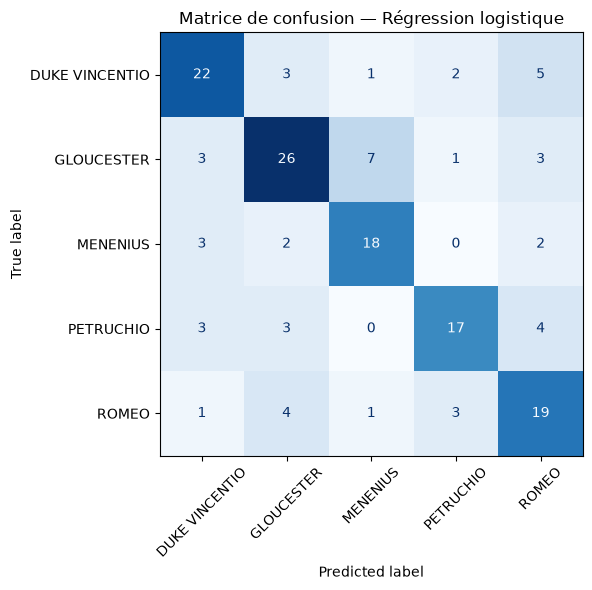

          vrai         prédit  erreurs  part de la classe
    GLOUCESTER       MENENIUS        7               0.18
DUKE VINCENTIO          ROMEO        5               0.15
         ROMEO     GLOUCESTER        4               0.14
     PETRUCHIO          ROMEO        4               0.15
DUKE VINCENTIO     GLOUCESTER        3               0.09
      MENENIUS DUKE VINCENTIO        3               0.12
     PETRUCHIO     GLOUCESTER        3               0.11
     PETRUCHIO DUKE VINCENTIO        3               0.11


In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur],
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"Matrice de confusion — {meilleur}")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, resultats[meilleur], labels=sorted(y_test.unique()))
labels = sorted(y_test.unique())
paires = []
for i, vrai in enumerate(labels):
    for j, pred in enumerate(labels):
        if i != j and cm[i, j] > 0:
            paires.append({
                "vrai": vrai,
                "prédit": pred,
                "erreurs": int(cm[i, j]),
                "part de la classe": cm[i, j] / cm[i].sum(),
            })
print(pd.DataFrame(paires).sort_values("erreurs", ascending=False).head(8).round(2).to_string(index=False))


In [14]:
# les termes qui poussent le plus vers chaque locuteur
modele = modeles_entraines["Régression logistique"]
termes = np.array(vectoriseur.get_feature_names_out())
for i, classe in enumerate(modele.classes_):
    top = np.argsort(modele.coef_[i])[-8:][::-1]
    print(f"{classe:<16} {', '.join(termes[top])}")


DUKE VINCENTIO   you, angelo, him, duke, provost, your, claudio, the duke
GLOUCESTER       king, clarence, lord, edward, my lord, cousin, god, warwick
MENENIUS         he, you, marcius, like, rome, you have, tribunes, pray
PETRUCHIO        kate, hortensio, come, and, sir, her, why, not
ROMEO            love, thy, thou, mercutio, goose, night, what shall, dream


In [15]:
erreurs = pd.DataFrame({
    "replique": X_test.values,
    "vrai": y_test.values,
    "prédit": resultats[meilleur],
})
erreurs = erreurs[erreurs["vrai"] != erreurs["prédit"]]
print(f"{len(erreurs)} erreurs sur {len(y_test)} répliques de test\n")
for _, r in erreurs.head(5).iterrows():
    print(f"{r['vrai']}  ->  {r['prédit']}")
    print(" ", r["replique"][:220])
    print()


51 erreurs sur 153 répliques de test

ROMEO  ->  PETRUCHIO
  Switch and spurs, switch and spurs; or I'll cry a match.

PETRUCHIO  ->  ROMEO
  Why, thou say'st true; it is a paltry cap, A custard-coffin, a bauble, a silken pie: I love thee well, in that thou likest it not.

PETRUCHIO  ->  GLOUCESTER
  Twenty crowns! I'll venture so much of my hawk or hound, But twenty times so much upon my wife.

GLOUCESTER  ->  ROMEO
  By so much is the wonder in extremes.

ROMEO  ->  GLOUCESTER
  O, I am fortune's fool!



### 8.3 Analyse des erreurs — la partie la plus importante

Répondez précisément, en vous appuyant sur des exemples concrets tirés de vos données.

1. **Quelles paires de locuteurs sont le plus confondues ?** Formulez une hypothèse : viennent-ils de la même pièce ? ont-ils un registre proche ? un nombre d'exemples très différent ?

2. **Sortez cinq répliques mal classées et lisez-les.** Auriez-vous su répondre vous-même ? Si non, que dit cela sur le plafond de performance atteignable ?

3. **Regardez les coefficients de votre modèle linéaire** (`coef_`) : quels termes pèsent le plus pour chaque classe ? Y a-t-il des **noms propres** parmi eux ?

   Si oui, posez-vous la vraie question : votre modèle reconnaît-il le **style d'un personnage**, ou identifie-t-il simplement la **pièce** dans laquelle la réplique apparaît ? Ce n'est pas du tout la même tâche, et cela change ce que vous pouvez affirmer sur votre modèle.

4. **Votre score est-il crédible ?** Reprenez votre pipeline et vérifiez qu'aucune information du test n'a pu remonter vers l'entraînement.

> *Analyse :*
>
> 1. La confusion la plus nette est Gloucester prédit Menenius (7 cas, 18 % de la classe). Ils ne sont pas dans la même pièce (Richard III et Coriolan), mais les deux parlent politique. Ensuite le Duc est prédit Romeo (5 cas) : ce ne sont pas les mêmes pièces non plus, ce sont des répliques assez neutres. Petruchio est prédit Romeo 4 fois, et l'inverse apparaît dans les exemples : tutoiement, amour, dispute. Gloucester, la classe la plus grosse, ramasse aussi des phrases trop courtes pour trancher.
>
> 2. Cinq erreurs, lues telles quelles :
>    - Romeo → Petruchio : « Switch and spurs, switch and spurs; or I'll cry a match. »
>    - Petruchio → Romeo : « ... I love thee well, in that thou likest it not. »
>    - Petruchio → Gloucester : « Twenty crowns! I'll venture so much of my hawk or hound... »
>    - Gloucester → Romeo : « By so much is the wonder in extremes. »
>    - Romeo → Gloucester : « O, I am fortune's fool! »
>    Je n'aurais pas su les attribuer non plus, sauf peut-être « I love thee » qui sonne Roméo. Ce sont des formules courtes, sans le nom de la scène. Le plafond n'est pas 100 % : une partie des répliques ne contient pas l'information.
>
> 3. Les coefficients de la régression (les plus forts par classe) sont surtout des noms propres et des mots de la pièce : Angelo, Claudio, provost pour le Duc ; Clarence, Edward, Warwick pour Gloucester ; Marcius, Rome, tribunes pour Menenius ; Kate, Hortensio pour Petruchio ; Mercutio, love, thou pour Romeo. Le modèle ne reconnaît pas vraiment un style. Il reconnaît la pièce, puis en déduit le personnage, puisqu'un nom comme Kate n'apparaît que chez Petruchio.
>
> 4. Le protocole est bon : le découpage est fait avant d'apprendre le vocabulaire, et le test ne sert qu'à transformer. Les proportions train et test collent. On ne peut pas en conclure que le modèle a appris le style. La partie 9 le mesure en retirant les noms propres.


## 9. Pour aller plus loin (optionnel)

Si vous avez terminé :

- **Validation croisée.** Remplacez le simple découpage par un `cross_val_score` en 5 folds sur le train. Regardez la **dispersion** des scores, pas seulement la moyenne. Un modèle à 0,82 ± 0,01 vaut souvent mieux qu'un modèle à 0,84 ± 0,09.

- **Comparer les représentations.** `CountVectorizer` (Bag of Words) contre `TfidfVectorizer`. L'écart est-il significatif ? Correspond-il à ce que le cours laissait prévoir ?

- **Faire varier la difficulté.** Passez de 5 à 10 locuteurs. Comment évoluent l'accuracy et le F1 macro ? Lequel des deux chute le plus, et pourquoi ?

- **Sur-apprentissage.** Comparez votre score sur le train et sur le test. L'écart vous dit-il quelque chose ? Que se passe-t-il quand vous faites varier `C` dans la régression logistique ?

- **Utiliser un `Pipeline` scikit-learn.** Encapsulez vectoriseur et modèle dans un `sklearn.pipeline.Pipeline`. Expliquez en une phrase pourquoi cette construction rend la fuite de données structurellement impossible.

---

## Rendu

Notebook exécuté, avec toutes les sorties visibles et **toutes les cellules de réponse remplies**.

Le barème porte autant sur la justification de vos choix et sur l'analyse des erreurs que sur le score obtenu.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=2000, C=1, class_weight="balanced", random_state=RANDOM_STATE
    )),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
print(scores.round(3))
print(f"moyenne {scores.mean():.3f}   écart-type {scores.std():.3f}")


[0.535 0.571 0.624 0.593 0.62 ]
moyenne 0.589   écart-type 0.033


In [17]:
comparaison = {}
for nom, vec in [
    ("Bag of Words", CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8)),
    ("TF–IDF", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)),
]:
    A = vec.fit_transform(X_train)
    B = vec.transform(X_test)
    m = LogisticRegression(max_iter=2000, C=1, class_weight="balanced", random_state=RANDOM_STATE)
    m.fit(A, y_train)
    pred = m.predict(B)
    comparaison[nom] = f1_score(y_test, pred, average="macro")
    print(f"{nom:<14} F1 macro {comparaison[nom]:.3f}")


Bag of Words   F1 macro 0.586
TF–IDF         F1 macro 0.668


In [18]:
def evaluer(n_locuteurs, min_mots=5):
    top = df["locuteur"].value_counts().head(n_locuteurs).index
    d = df[df["locuteur"].isin(top)].query("n_mots >= @min_mots")
    xa, xb, ya, yb = train_test_split(
        d["replique"], d["locuteur"], test_size=0.2,
        stratify=d["locuteur"], random_state=RANDOM_STATE,
    )
    v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)
    A, B = v.fit_transform(xa), v.transform(xb)
    m = LogisticRegression(max_iter=2000, C=1, class_weight="balanced", random_state=RANDOM_STATE)
    m.fit(A, ya)
    pred = m.predict(B)
    base = DummyClassifier(strategy="most_frequent").fit(A, ya).predict(B)
    return {
        "classes": n_locuteurs,
        "exemples": len(d),
        "F1 macro": f1_score(yb, pred, average="macro"),
        "accuracy": accuracy_score(yb, pred),
        "baseline accuracy": accuracy_score(yb, base),
    }

print(pd.DataFrame([evaluer(5), evaluer(10)]).round(3).to_string(index=False))


 classes  exemples  F1 macro  accuracy  baseline accuracy
       5       761     0.668     0.667              0.261
      10      1310     0.418     0.439              0.149


In [19]:
# C plus grand = moins de régularisation. On compare train et test.
for C in (0.1, 1, 5):
    m = LogisticRegression(max_iter=2000, C=C, class_weight="balanced", random_state=RANDOM_STATE)
    m.fit(Xtr, y_train)
    f_train = f1_score(y_train, m.predict(Xtr), average="macro")
    f_test = f1_score(y_test, m.predict(Xte), average="macro")
    print(f"C={C:<4}  train {f_train:.3f}   test {f_test:.3f}")


C=0.1   train 0.939   test 0.616
C=1     train 0.985   test 0.668
C=5     train 1.000   test 0.669


In [20]:
# heuristique grossière : tout mot qui apparaît quelque part avec une majuscule
noms_propres = {mot.lower() for mot in re.findall(r"\b[A-Z][a-z]{2,}\b", texte)}
print(f"{len(noms_propres):,} candidats (la majuscule de début de phrase est comptée aussi)")

def retirer_noms(docs):
    return [" ".join(w for w in doc.split() if w.lower() not in noms_propres) for doc in docs]

vec_sans = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)
A = vec_sans.fit_transform(retirer_noms(X_train))
B = vec_sans.transform(retirer_noms(X_test))
m = LogisticRegression(max_iter=2000, C=1, class_weight="balanced", random_state=RANDOM_STATE)
m.fit(A, y_train)
pred = m.predict(B)
print(f"F1 macro sans ces mots : {f1_score(y_test, pred, average='macro'):.3f}")
print(f"F1 macro avec eux     : {tableau.loc['Régression logistique', 'F1 macro']:.3f}")


2,557 candidats (la majuscule de début de phrase est comptée aussi)
F1 macro sans ces mots : 0.582
F1 macro avec eux     : 0.668


> Lecture de ces essais.
>
> La validation croisée sur le train donne un F1 macro de 0,59, avec un écart-type de 0,03. C'est stable, et en dessous du 0,67 du découpage test : un seul split ne suffit pas à annoncer le score.
>
> Le TF–IDF fait mieux que le simple comptage (0,67 contre 0,59). C'est ce que le cours laisse attendre : les mots présents partout sont baissés.
>
> À 10 locuteurs, le F1 macro passe de 0,67 à 0,42 et l'accuracy de 0,67 à 0,44. Les deux baissent à peu près autant. La baseline d'accuracy passe de 0,26 à 0,15, donc une partie de la baisse vient juste du fait que la classe majoritaire pèse moins.
>
> Avec C=5 le train est à 1,0 et le test reste à 0,67. Le modèle retient les répliques d'entraînement. C=1 garde le même test, avec un train à 0,98. C=0.1 réduit l'écart, mais le test baisse à 0,62.
>
> Le Pipeline réapprend le vectoriseur dans chaque fold. L'IDF est calculé sur le train du fold, jamais sur la partie qu'on évalue.
>
> En retirant les mots qui apparaissent en majuscule, le F1 passe de 0,67 à 0,58. L'heuristique est large, elle prend aussi les débuts de phrase, donc c'est un ordre de grandeur. La chute, plus les coefficients remplis de prénoms, va dans le même sens : une partie du score vient de la pièce, pas du style.
